# Evidencia de Aprendizaje 2 — Optimizando la productividad en el mundo del software

Kevin Daniel Sepúlveda Giraldo<br>
Jessica Serna Vargas<br>
Grupo 9 · Programación para Análisis de Datos — PREICA2602B020048<br>
Docente: Andrés Felipe Palacio<br>
IU Digital de Antioquia

---

## Planteamiento
En la EA1 hice el scraping del catálogo de **tenis para hombre de Tiendas Branchos** en un solo cuaderno de Colab.
Funcionó, pero tenía tres problemas: el código estaba todo mezclado en celdas, no tenía pruebas y para actualizar
los datos tenía que volver a correr todo a mano.

En esta evidencia tomé ese mismo trabajo y lo convertí en un proyecto con **control de versiones en GitHub** y un
flujo **DevOps con GitHub Actions**:

| Pieza | Qué hace |
|-------|----------|
| Repositorio | https://github.com/kevinsepulveda-iud/branchos-precios-devops |
| Ramas | `main` + `feature/scraping`, `feature/procesamiento`, `feature/despliegue`, integradas con pull requests |
| CI (`ci.yml`) | En cada push o PR corre `ruff` y las pruebas de `pytest` en Python 3.10, 3.11 y 3.12 |
| Scraping programado | Todos los lunes extrae el catálogo, valida que esté completo y lo guarda en `data/historico/` |
| CD (`cd.yml`) | Cada cambio en `main` vuelve a probar, genera el reporte y lo publica en GitHub Pages |
| Reporte | https://kevinsepulveda-iud.github.io/branchos-precios-devops/ |

Este cuaderno muestra el proyecto paso a paso. Funciona en Colab (clona el repositorio) y en Jupyter local.

## 0. Preparar el entorno

In [1]:
import sys, subprocess, json
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
REPO = "https://github.com/kevinsepulveda-iud/branchos-precios-devops.git"

if EN_COLAB:
    # En Colab clono el repositorio y trabajo dentro de él
    if not Path("branchos-precios-devops").exists():
        subprocess.run(["git", "clone", REPO], check=True)
    RAIZ = Path("branchos-precios-devops").resolve()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(RAIZ / "requirements-dev.txt")], check=True)
else:
    # En local el cuaderno está en notebooks/, entonces la raíz es la carpeta de arriba
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(RAIZ / "src"))   # para importar el paquete branchos
print("Entorno:", "Google Colab" if EN_COLAB else "Jupyter local")
print("Carpeta del proyecto:", RAIZ.name)

Entorno: Jupyter local
Carpeta del proyecto: branchos-precios-devops


## 1. Control de versiones con Git y GitHub

En la clase de la semana 4 el profe mostró cómo clonar un repositorio desde Colab, copiar el CSV del scraping y
hacer `add`, `commit` y `push` con un token. Yo seguí la misma idea pero trabajé con **ramas y pull requests**, que
es lo que se usa en un equipo de desarrollo:

```bash
git clone https://github.com/kevinsepulveda-iud/branchos-precios-devops.git
git checkout -b feature/scraping          # una rama por funcionalidad
git add src/branchos/scraper.py tests/
git commit -m "feat(scraping): extracción con reintentos y segunda pasada"
git push origin feature/scraping          # GitHub corre el CI sobre la rama
# en GitHub: Pull request feature/scraping -> main, revisar que el CI esté en verde y hacer merge
```

| Rama | Contenido |
|------|-----------|
| `feature/scraping` | `scraper.py`, `limpieza.py`, pruebas con una página real guardada, `scripts/extraer.py`, CI |
| `feature/procesamiento` | `analisis.py`, `reporte.py`, `scripts/publicar.py`, dataset del 9 de noviembre |
| `feature/despliegue` | `cd.yml`, `scraping-programado.yml`, `Dockerfile` y este cuaderno |

Una diferencia con el ejemplo de clase: **no escribo el token dentro del cuaderno**. Si quiero hacer push desde
Colab lo leo de los *Secretos* de Colab, así no queda expuesto si comparto el archivo:

```python
from google.colab import userdata
token = userdata.get("GITHUB_TOKEN")
```

## 2. Integración continua: pruebas automáticas

Separé el código de la EA1 en funciones pequeñas dentro de `src/branchos/` para poder probarlas una por una.
Las pruebas del scraper usan un recorte de una página real de Branchos guardada en `tests/fixtures/`, así que
corren sin internet y no le hacen peticiones a la tienda cada vez que hago un push.

Esto es exactamente lo que ejecuta GitHub Actions en cada push:

In [2]:
# Revisión de estilo (el mismo comando del workflow ci.yml)
r = subprocess.run(["ruff", "check", "."], cwd=RAIZ, capture_output=True, text=True)
print(r.stdout or r.stderr)

All checks passed!



In [3]:
# Pruebas unitarias
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "--no-header", "-p", "no:cacheprovider"],
                   cwd=RAIZ, capture_output=True, text=True)
print(r.stdout[-3500:])

==
collecting ... collected 40 items

tests/test_analisis.py::test_indicadores PASSED                          [  2%]
tests/test_analisis.py::test_por_marca_ordena_por_referencias PASSED     [  5%]
tests/test_analisis.py::test_rangos_suman_100 PASSED                     [  7%]
tests/test_analisis.py::test_comparar_extracciones PASSED                [ 10%]
tests/test_analisis.py::test_generar_sitio PASSED                        [ 12%]
tests/test_limpieza.py::test_a_pesos[$ 191.200,00-191200] PASSED         [ 15%]
tests/test_limpieza.py::test_a_pesos[$ 215.200-215200] PASSED            [ 17%]
tests/test_limpieza.py::test_a_pesos[191200-191200] PASSED               [ 20%]
tests/test_limpieza.py::test_a_pesos[263200-263200] PASSED               [ 22%]
tests/test_limpieza.py::test_a_pesos[263200.0-263200] PASSED             [ 25%]
tests/test_limpieza.py::test_a_pesos[-None] PASSED                       [ 27%]
tests/test_limpieza.py::test_a_pesos[None-None] PASSED                   [ 30%]
te

Algunas pruebas salen directamente de problemas que encontré en la EA1:

- `test_reintenta_cuando_la_pagina_llega_vacia`: la tienda a veces responde una página sin productos.
- `test_segunda_pasada_recupera_paginas_fallidas`: en vez de unir dos métodos (BeautifulSoup + Scrapy) como en la EA1, ahora vuelvo a pedir solo las páginas que fallaron.
- `test_validar_detecta_extraccion_incompleta`: si se extrae menos del 95 % de lo que reporta la tienda, el pipeline falla y **no se publica**.
- `test_nombres_con_entidades_html`: en esta extracción apareció `D&quot;lites` en el nombre de un producto Skechers.

## 3. Extracción (fase de datos de CRISP-DM)

`scripts/extraer.py` corre el scraper completo, limpia los datos, los valida y los guarda con la fecha. El
workflow `scraping-programado.yml` lo ejecuta solo todos los lunes a las 6:00 a. m.

La extracción completa tarda unos 4 minutos por la pausa de 1,5 s entre páginas. Para no volver a cargar la
tienda cada vez que abro el cuaderno, dejo la variable en `False` y leo el dataset que ya está versionado en el
repositorio (extracción del 9 de noviembre de 2026).

In [4]:
EJECUTAR_SCRAPING = False   # cambiar a True para extraer de nuevo (unos 4 minutos)

if EJECUTAR_SCRAPING:
    r = subprocess.run([sys.executable, "scripts/extraer.py"], cwd=RAIZ, capture_output=True, text=True)
    print(r.stderr[-2000:])

resumen = json.loads((RAIZ / "data" / "ultima_ejecucion.json").read_text(encoding="utf-8"))
print(f"Fecha de extracción:      {resumen['fecha']}")
print(f"Productos que reporta la tienda: {resumen['total_reportado']}")
print(f"Páginas recorridas:       {resumen['paginas']}")
print(f"Registros extraídos:      {resumen['registros']}  "
      f"({resumen['registros'] / resumen['total_reportado'] * 100:.1f} % del catálogo)")
print(f"Páginas sin leer:         {resumen['paginas_fallidas']}")
print(f"Tiempo:                   {resumen['segundos']} s")
print(f"Problemas de calidad:     {resumen['problemas'] or 'ninguno'}")

Fecha de extracción:      2026-11-09
Productos que reporta la tienda: 560
Páginas recorridas:       47
Registros extraídos:      548  (97.9 % del catálogo)
Páginas sin leer:         [28]
Tiempo:                   204.8 s
Problemas de calidad:     ninguno


In [5]:
import pandas as pd
from branchos import analisis, limpieza

df = pd.read_csv(RAIZ / "data" / "tenis_branchos_actual.csv", sep=";", encoding="utf-8-sig", dtype={"sku": str})
print(df.shape)
df.head(8)

(548, 11)


,fecha_extraccion,sku,nombre,marca,tipo,precio,precio_antes,descuento_pct,tallas_disponibles,url,pagina
0,2026-11-09,154300,Nike Tenis Revolution 8 Hombre Negro,Nike,Tenis,263200,359000,26.7,5,https://www.tiendasbranchos.com/nike-tenis-revolution-8-hombre-negro-66091/p,1
1,2026-11-09,161724,Nike Teniguayo Total 90 Hombre Cafe,Nike,Teniguayos,273000,659000,58.6,8,https://www.tiendasbranchos.com/nike-teniguayo-total-90-hombre-cafe-67352/p,1
2,2026-11-09,76224,Fila Botas Netball Classic Hombre Blanco,Fila,Botas,239000,269000,11.2,7,https://www.tiendasbranchos.com/fila-botas-netball-classic-hombre-blanco-46647/p,1
3,2026-11-09,104906,Nike Tenis Court Vision Mid Hombre Blanco,Nike,Tenis,312000,499000,37.5,4,https://www.tiendasbranchos.com/nike-tenis-court-vision-mid-hombre-blanco-55403/p,1
4,2026-11-09,104552,Nike Tenis Sb Chron 2 Hombre Negro,Nike,Tenis,288000,429000,32.9,3,https://www.tiendasbranchos.com/nike-tenis-sb-chron-2-hombre-negro-54266/p,1
5,2026-11-09,149081,Treme Tenis Beltoro Hombre Blanco,Treme,Tenis,80000,179000,55.3,5,https://www.tiendasbranchos.com/treme-tenis-beltoro-hombre-blanco-61586/p,1
6,2026-11-09,158193,Nike Tenis Flex Train Hombre Negro,Nike,Tenis,280000,459000,39.0,2,https://www.tiendasbranchos.com/nike-tenis-flex-train-hombre-negro-66564/p,1
7,2026-11-09,137697,Fila Guayos Hyperflex Tf Hombre Verde Neon,Fila,Guayos,130000,269000,51.7,3,https://www.tiendasbranchos.com/fila-guayos-hyperflex-tf-hombre-verde-neon-58840/p,1


In [6]:
# El mismo control de calidad que usa el pipeline antes de publicar
print("Problemas encontrados:", limpieza.validar(df, total_reportado=resumen["total_reportado"]) or "ninguno")
print("Completitud de campos clave:")
print((df[["nombre", "marca", "precio", "precio_antes", "url"]].notna().mean() * 100).round(1).to_string())

Problemas encontrados: ninguno
Completitud de campos clave:
nombre          100.0
marca           100.0
precio          100.0
precio_antes    100.0
url             100.0


## 4. Resultados: ¿qué cambió desde la EA1?

Como ahora cada extracción queda guardada con su fecha, puedo comparar el catálogo del 19 de octubre (EA1) con el
del 9 de noviembre.

In [7]:
ind = analisis.indicadores(df)
ea1 = {"referencias": 593, "marcas": 7, "precio_promedio": 220234, "precio_mediano": 210000,
       "pct_con_descuento": 98.0, "descuento_promedio": 37.5, "pct_descuento_50_o_mas": 19.6,
       "tallas_promedio": 5.9}

comparacion = pd.DataFrame({"EA1 (19 oct)": ea1, "EA2 (9 nov)": {k: ind[k] for k in ea1}})
comparacion["cambio"] = comparacion["EA2 (9 nov)"] - comparacion["EA1 (19 oct)"]
comparacion

,EA1 (19 oct),EA2 (9 nov),cambio
referencias,593.0,548.0,-45.0
marcas,7.0,7.0,0.0
precio_promedio,220234.0,263966.0,43732.0
precio_mediano,210000.0,259000.0,49000.0
pct_con_descuento,98.0,100.0,2.0
descuento_promedio,37.5,24.0,-13.5
pct_descuento_50_o_mas,19.6,8.4,-11.2
tallas_promedio,5.9,5.7,-0.2


In [8]:
analisis.por_marca(df)

,marca,referencias,precio_promedio,descuento_promedio,tallas_promedio
0,Fila,133,195289,21.1,6.5
1,Nike,129,355261,35.5,4.6
2,Skechers,85,326298,13.9,6.1
3,Treme,66,118917,31.5,5.6
4,Puma,60,249408,26.2,6.0
5,Adidas,51,315278,12.7,5.1
6,Reebok,24,259333,11.6,6.5


In [9]:
analisis.rangos_precio(df).rename("% de referencias")

,% de referencias
precio,
< $150 mil,23.2
$150-250 mil,24.8
$250-350 mil,35.0
> $350 mil,17.0


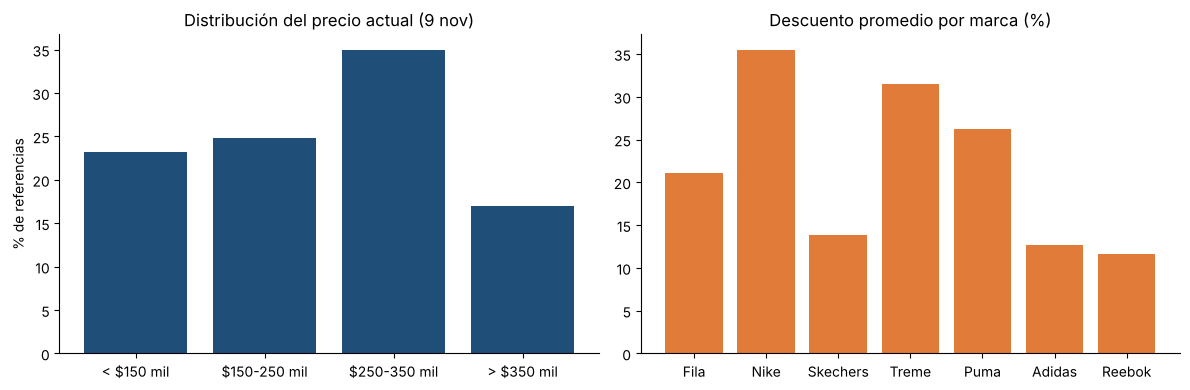

In [10]:
import matplotlib.pyplot as plt
from branchos import reporte

marcas = analisis.por_marca(df)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rangos = analisis.rangos_precio(df)
ax[0].bar(rangos.index, rangos.values, color="#1f4e79")
ax[0].set_title("Distribución del precio actual (9 nov)")
ax[0].set_ylabel("% de referencias")
x = range(len(marcas))
ax[1].bar(x, marcas["descuento_promedio"], color="#e07b39")
ax[1].set_xticks(list(x), marcas["marca"])
ax[1].set_title("Descuento promedio por marca (%)")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

In [11]:
# Los descuentos más altos de esta extracción
df.sort_values("descuento_pct", ascending=False)[["nombre", "precio", "precio_antes", "descuento_pct"]].head(8)

,nombre,precio,precio_antes,descuento_pct
1,Nike Teniguayo Total 90 Hombre Cafe,273000,659000,58.6
187,Nike Teniguayo Total 90 Hombre Dorado,273000,659000,58.6
332,Fila Tenis Ditra Hombre Blanco,110000,259000,57.5
335,Fila Tenis Korac Hombre Negro,110000,259000,57.5
268,Fila Tenis Korac Hombre Blanco,110000,259000,57.5
392,Fila Tenis Ditra Hombre Blanco,110000,259000,57.5
341,Treme Tenis Orran Hombre Blanco,81000,189000,57.1
334,Treme Tenis Vohe Hombre Blanco,81000,189000,57.1


**Lo que encontré:**

- El catálogo bajó de 593 a 560 referencias según la tienda (extraje 548; la página 28 respondió vacía en los tres
  intentos y en la segunda pasada, igual que me pasó con algunas páginas en la EA1). La cobertura fue del 97,9 %,
  por encima del mínimo de 95 % que puse en el control de calidad.
- Los descuentos bajaron bastante: el descuento promedio pasó de 37,5 % a 24,0 % y los productos con rebaja de 50 %
  o más pasaron de 19,6 % a 8,4 %. Al mismo tiempo el precio mediano subió de \$210.000 a \$259.000. Todos los
  productos siguen mostrando precio tachado.
- Nike sigue siendo la marca más cara (\$355.261 en promedio) y la que más descuenta (35,5 %); Treme sigue siendo
  la más económica.

Esto confirma lo que dejé como siguiente paso en la EA1: con una sola foto no se podía saber si los descuentos eran
reales o permanentes. Con el scraping semanal el histórico va a crecer solo.

## 5. Entrega continua: generar y publicar el reporte

`scripts/publicar.py` genera una página HTML con los indicadores, los gráficos y el CSV para descargar. El workflow
`cd.yml` la publica en GitHub Pages cada vez que hay un cambio en `main`, pero solo si las pruebas pasan.

In [12]:
r = subprocess.run([sys.executable, "scripts/publicar.py", "--salida", "site", "--version", "notebook"],
                   cwd=RAIZ, capture_output=True, text=True)
print(r.stdout or r.stderr)
print(sorted(p.name for p in (RAIZ / "site").iterdir()))

Sitio generado en site/index.html

['historico.png', 'index.html', 'indicadores.json', 'marcas.png', 'rangos.png', 'tenis_branchos_actual.csv']


## 6. Conclusiones

1. Pasar el código de un cuaderno a un paquete con funciones pequeñas fue lo que más trabajo me dio, pero es lo que
   permite probarlo: ahora hay 40 pruebas que corren en tres versiones de Python cada vez que subo un cambio.
2. Las ramas y los pull requests me obligaron a dividir el trabajo en partes (scraping, procesamiento, despliegue)
   y a revisar que el CI estuviera en verde antes de integrar a `main`.
3. El control de calidad automático es la pieza más importante del pipeline: si la tienda falla y el scraping
   sale incompleto, el workflow se detiene y el reporte publicado no se daña.
4. Con el scraping programado el análisis deja de ser una foto: en tres semanas el descuento promedio bajó 13,5
   puntos y el precio mediano subió \$49.000.
5. Para la EA3 queda pendiente convertir el reporte estático en una aplicación web y desplegarla en la nube.